# Take-Home Exercise 1: From Data to Evidence
## Assignment Details
**Module Title:** Data Analytics  
**CRN:** 23631
**Student:** Rory Patrick Sheridan - A00082654  
**Submission File:** `A00082654_Rory_Sheridan_A1.pdf`  
**Dataset:**
FreshPack Foods batch-level production and quality data, `Take_Home_LabExercise_1_Dataset.csv`.  
**Task:**
Inspect a dataset, identify data-quality issues, choose suitable summaries and visualisations, quantify patterns, apply introductory statistical inference, and communicate what the evidence does and does not support.

Github Repository:  
https://github.com/Ri-Dearg/da-labs  
Github Notebook:  
https://github.com/Ri-Dearg/da-labs/blob/main/lab1_data_evidence.ipynb

## Summary
**Findings TBD**

## Table of Contents

<details>
<summary><a href="#tools--libraries">Tools & Libraries</a></summary>

- [Libraries](#libraries)

</details>
<details>
<summary><a href="#question-1-understand-and-audit-the-data">Question 1: Understand and Audit the Data</a></summary>

- [Go to section](#question-1-understand-and-audit-the-data)

</details>


## Tools & Libraries
1. [Pandas](https://pandas.pydata.org) - Dataframes and data manipulation
2. [Jupyter](https://jupyter.org) - Notebook Tool

### Libraries
Libraries used.

In [32]:
import pandas as pd
import scipy.stats as stats
import seaborn as sns

## Question 1: Understand and Audit the Data


### a) Identify the observational unit. For each variable, classify it as identifier/date/categorical/ordinal/quantitative and, where relevant, state the measurement scale.

**Observational unit:** One batch of food.

| Variable Name | Type | Measurement Scale | Unit |
|---|---|---|---|
| `Batch_ID` | Identifier | Nominal |  |
| `Production_Date` | Date | Interval | Day |
| `Factory` | Categorical | Nominal |  |
| `Process_Type` | Categorical | Nominal |  |
| `Shift` | Categorical | Nominal |  |
| `Product_Weight_g` | quantitative | Ratio | Grams |
| `Moisture_pct` | quantitative | Ratio | Percent |
| `Temperature_C` | quantitative | Interval | Celsius |
| `Processing_Time_min` | quantitative | Ratio | Minute |
| `Quality_Grade` | Ordinal | Ordinal |  |
| `Defect` | Categorical | Nominal |  |

In [33]:
# Import data
df = pd.read_csv('products.csv')
df.head()

,Batch_ID,Production_Date,Factory,Process_Type,Shift,Product_Weight_g,Moisture_pct,Temperature_C,Processing_Time_min,Quality_Grade,Defect
0,B001,2026-09-17,B,Enhanced,Day,482.9,11.18,21.0,33.5,B,Yes
1,B002,2026-09-07,C,Standard,Day,496.3,11.17,22.1,33.6,A,No
2,B003,2026-09-14,B,Standard,Night,492.3,11.65,20.5,35.8,A,No
3,B004,2026-09-16,C,Standard,Day,513.1,11.55,20.5,37.6,B,No
4,B005,2026-09-10,A,Enhanced,Day,494.5,12.57,21.6,45.7,B,Yes


In [34]:
# Explore structure of the data
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 120 entries, 0 to 119
Data columns (total 11 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Batch_ID             120 non-null    str    
 1   Production_Date      120 non-null    str    
 2   Factory              120 non-null    str    
 3   Process_Type         120 non-null    str    
 4   Shift                120 non-null    str    
 5   Product_Weight_g     120 non-null    float64
 6   Moisture_pct         118 non-null    float64
 7   Temperature_C        120 non-null    float64
 8   Processing_Time_min  119 non-null    float64
 9   Quality_Grade        119 non-null    str    
 10  Defect               120 non-null    str    
dtypes: float64(4), str(7)
memory usage: 10.4 KB


### b) Audit the dataset before analysis. Quantify missing values, duplicated records, suspicious or implausible values, and any other data-quality issue you consider material.

Audit:
- Four missing values: 2 in `Moisture_pct`, 1 in `Processing_Time_min`, and 1 in `Quality_Grade`.
- 1 duplicated record on row 118, `Batch_ID` B048 .
- 1 suspicious value on `Product_Weight_g` at 568g, another on `Processing_Time_min` at 112, 1 implausible value on `Temperature_C` at 210.0.
- `Quality_Grade` and `Defect` don't align although it appears they should.
- `Production_Date` is type `str` rather than `DateTime`

In [35]:
# View data stats
df.describe()

,Product_Weight_g,Moisture_pct,Temperature_C,Processing_Time_min
count,120.000000,118.000000,120.000000,119.000000
mean,501.530833,11.660339,23.077500,41.831933
std,11.582621,0.701214,17.243888,8.606560
min,476.200000,9.610000,18.200000,26.400000
25%,494.775000,11.190000,20.800000,37.750000
50%,501.800000,11.660000,21.500000,41.700000
75%,508.700000,12.097500,22.200000,44.950000
max,568.000000,13.510000,210.000000,112.000000


In [36]:
# View categorical stats
df.describe(exclude='number')

,Batch_ID,Production_Date,Factory,Process_Type,Shift,Quality_Grade,Defect
count,120,120,120,120,120,119,120
unique,119,27,3,2,2,3,2
top,B048,2026-09-17,A,Standard,Day,B,No
freq,2,9,45,65,79,77,107


In [37]:
# Show cols and rows
df.shape

(120, 11)

In [38]:
# Check for duplicates
df.duplicated().sum()

np.int64(1)

In [39]:
# Show duplicates
df[df.duplicated()]

,Batch_ID,Production_Date,Factory,Process_Type,Shift,Product_Weight_g,Moisture_pct,Temperature_C,Processing_Time_min,Quality_Grade,Defect
118,B048,2026-09-18,A,Standard,Day,488.5,12.18,23.0,37.7,B,No


In [40]:
# Check for missing values
df.isna().sum()

Batch_ID               0
Production_Date        0
Factory                0
Process_Type           0
Shift                  0
Product_Weight_g       0
Moisture_pct           2
Temperature_C          0
Processing_Time_min    1
Quality_Grade          1
Defect                 0
dtype: int64

### c) Produce a short data-treatment log stating what you would keep, correct, exclude, or leave unchanged and why. State the analysis sample size(s) resulting from your decisions.

The set began with 120 rows. After data treatment 1 duplicate was removed and 119 rows remained.

- The duplicate shared the value `B048` with another row. All other values are also identical. Since the batch identifier should be a unique value, and all other rows have unique identifiers, I have chosen to drop it.
- There were four rows with missing values, which is a minimal amount of missing data for the dataset, so I chose to simply keep the rows. If issues arise later, I will reexamine the choice.
- The implausible temperature value of 210 seemed like erroneous data entry, as a decimal point would place it within a normal range. I have chosen to correct it directly as 21.0 For this reason.
- The other two values did not indicate erroneous data entry, so I have chosen to keep them in the case they are genuine.
- I changed the `Production_Date` to a `datetime` type so dates are stored and interpreted correctly.

In [41]:
# Drop duplicates and check for duplicates again
df_dedup = df.drop_duplicates()
df_dedup.duplicated().sum()

np.int64(0)

In [42]:
# Correct temperature value
df_temp = df_dedup.replace({'Temperature_C': {210: 21.0}})
df_temp.describe()

,Product_Weight_g,Moisture_pct,Temperature_C,Processing_Time_min
count,119.000000,117.000000,119.000000,118.000000
mean,501.640336,11.655897,21.489916,41.866949
std,11.569051,0.702561,1.124488,8.634745
min,476.200000,9.610000,18.200000,26.400000
25%,494.900000,11.190000,20.800000,37.800000
50%,502.000000,11.650000,21.500000,41.800000
75%,508.900000,12.090000,22.200000,44.975000
max,568.000000,13.510000,24.100000,112.000000


In [43]:
# Change Production_Date to datetime format
df_temp['Production_Date'] = df_temp['Production_Date'].astype('datetime64[ns]')
df_clean = df_temp.copy()

In [44]:
df_clean.head()

,Batch_ID,Production_Date,Factory,Process_Type,Shift,Product_Weight_g,Moisture_pct,Temperature_C,Processing_Time_min,Quality_Grade,Defect
0,B001,2026-09-17,B,Enhanced,Day,482.9,11.18,21.0,33.5,B,Yes
1,B002,2026-09-07,C,Standard,Day,496.3,11.17,22.1,33.6,A,No
2,B003,2026-09-14,B,Standard,Night,492.3,11.65,20.5,35.8,A,No
3,B004,2026-09-16,C,Standard,Day,513.1,11.55,20.5,37.6,B,No
4,B005,2026-09-10,A,Enhanced,Day,494.5,12.57,21.6,45.7,B,Yes


In [45]:
# Check remaining rows
print(df.shape[0] - df_clean.shape[0])
df_clean.shape[0]

1


119

## Question 2 - Explore, quantify and visualise

### a) Construct one compact descriptive table for the main quantitative variables. Select statistics that are appropriate to the shape and quality of the data. Include at least one robust measure where it adds value, and explain your choices briefly.

- Count was chosen to demonstrate some features have missing data.
- Mean and Median are quite similar, showing extreme values do not impact the mean in this case.
- SD shows that it is affected by the more extreme values in '`Product_Weight_g` and `Processing_Time_min`.
- IQR is the robust statistic as it is not impacted by the large values, like SD.
- Likewise, Skew is affected by these same values.
- Min and Max show the extreme values.

| Variable | count | Mean | Median | SD | IQR | Skew | Min | Max |
|---|---|---|---|---|---|---|---|---|
| `Product_Weight_g` | 119 | 501.64 | 502.00 | 11.57 | 14.00 | 1.36 | 476.20 | 568.00 |
| `Moisture_pct` | 117 | 11.66 | 11.65 | 0.70 | 0.90 | 0.10 | 9.61 | 13.51 |
| `Temperature_C` | 119 | 21.49 | 21.50 | 1.12 | 1.40 | -0.11 | 18.20 | 24.10 |
| `Processing_Time_min` | 118 | 41.87 | 41.80 | 8.63 | 7.18 | 4.53 | 26.40 | 112.00 |

In [46]:
# Show stats from quantitative cols.
cols = ['Product_Weight_g', 'Moisture_pct', 'Temperature_C', 'Processing_Time_min']


def iqr(s):
    return s.quantile(0.75) - s.quantile(0.25)


df_clean[cols].agg(['count', 'mean', 'median', 'std', iqr, 'skew', 'min', 'max']).T.round(
    2
)

,count,mean,median,std,iqr,skew,min,max
Product_Weight_g,119.0,501.64,502.00,11.57,14.00,1.36,476.20,568.00
Moisture_pct,117.0,11.66,11.65,0.70,0.90,0.10,9.61,13.51
Temperature_C,119.0,21.49,21.50,1.12,1.40,-0.11,18.20,24.10
Processing_Time_min,118.0,41.87,41.80,8.63,7.18,4.53,26.40,112.00


### b) Produce no more than five well-designed figures that collectively examine: (i) at least one distribution, (ii) at least one comparison across groups, (iii) at least one categorical pattern, and (iv) at least one relationship between two quantitative variables.

1. Histogram showing outlier value for Product_Weight_g.  
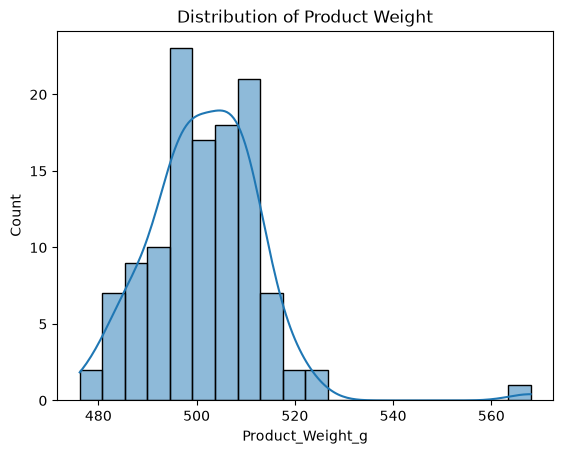  

0. Boxplot Showing Factory B produces more outliers.  
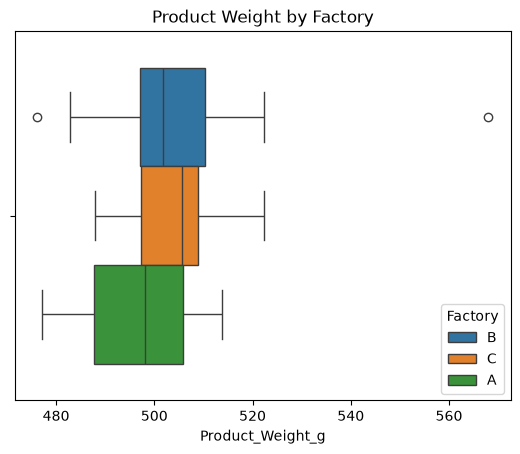  


1. Heatmap showing correlation between quantitative features.  
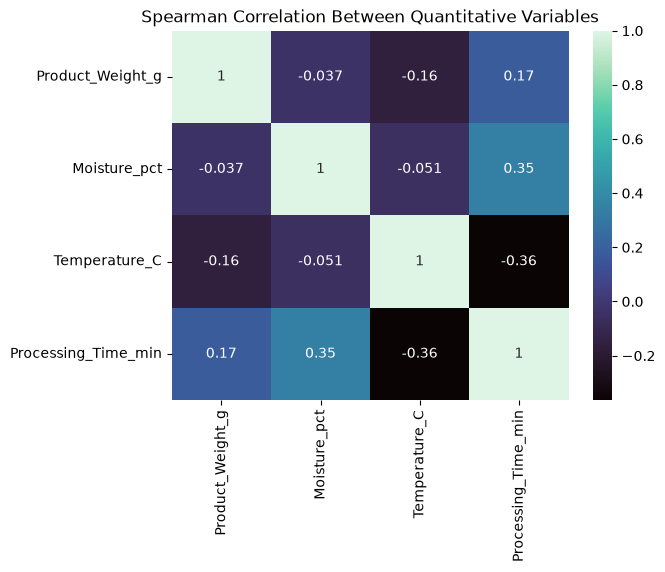  


0. Countplot to show differences in Quality_Grade.  
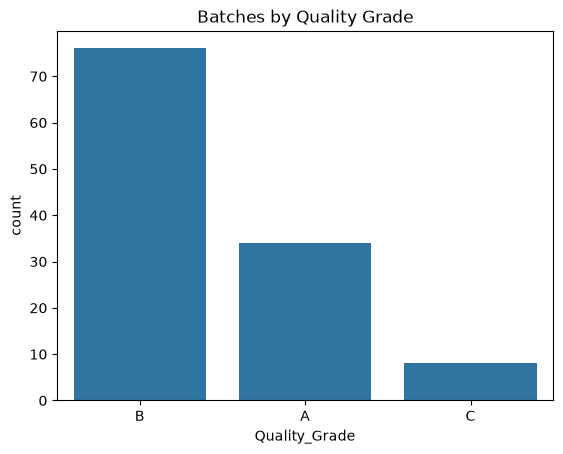  


0. Scatterplot to show the two most correlated items.  
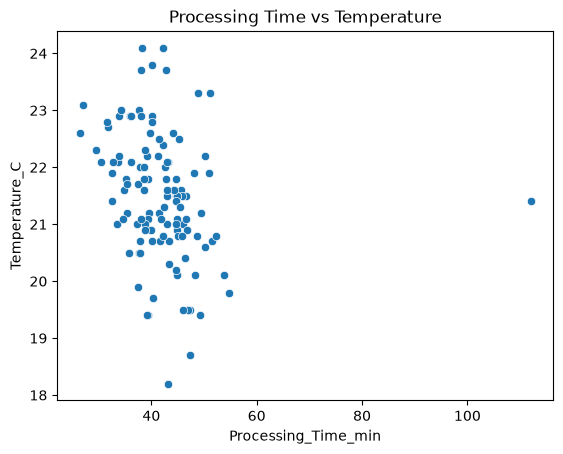
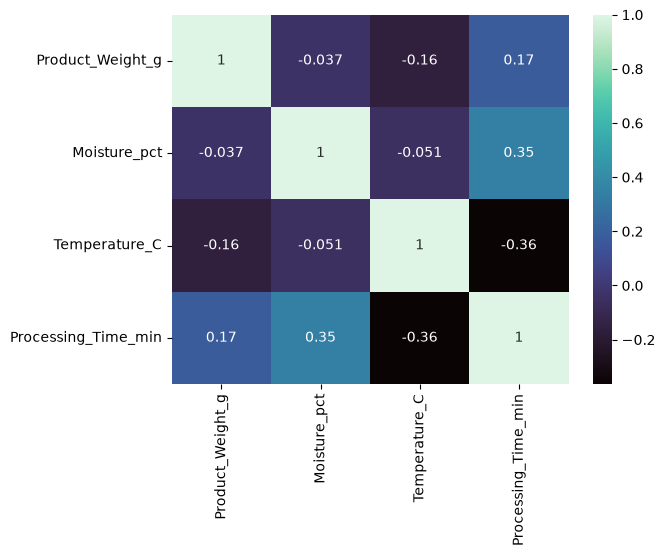
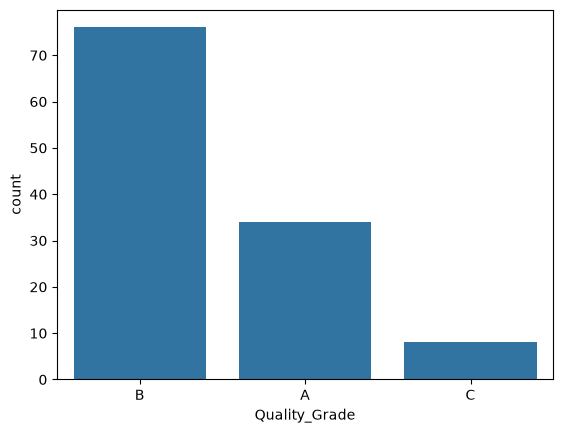
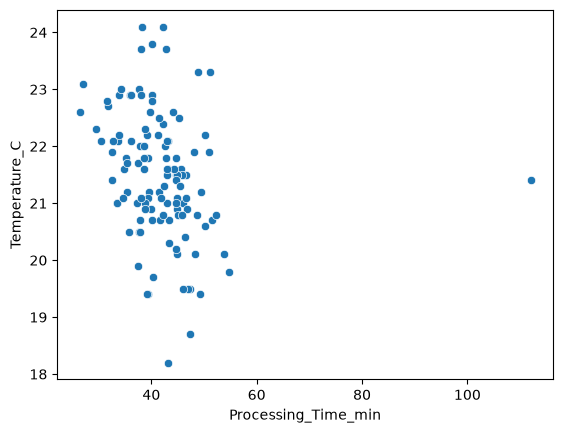
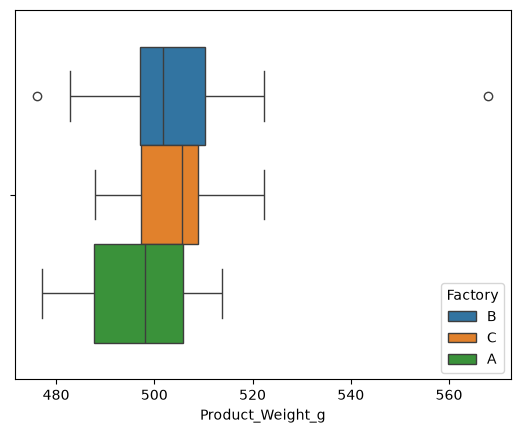
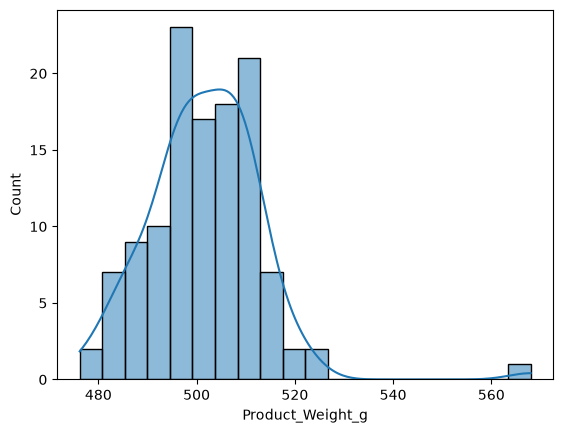

[Text(0.5, 1.0, 'Distribution of Product Weight')]

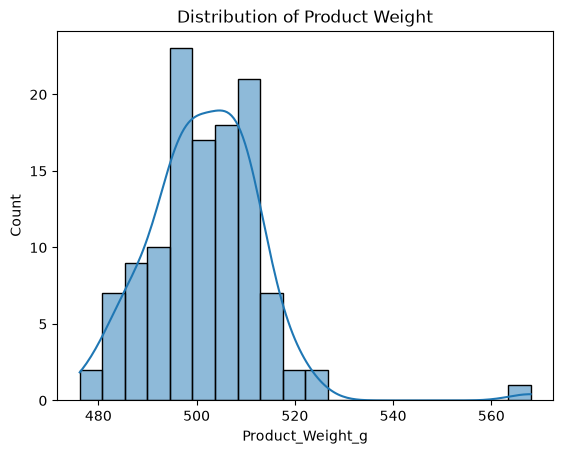

In [47]:
# Histogram showing outlier value for Product_Weight_g
sns.histplot(data=df_clean, x='Product_Weight_g', bins=20, kde=True).set(
    title='Distribution of Product Weight'
)

[Text(0.5, 1.0, 'Product Weight by Factory')]

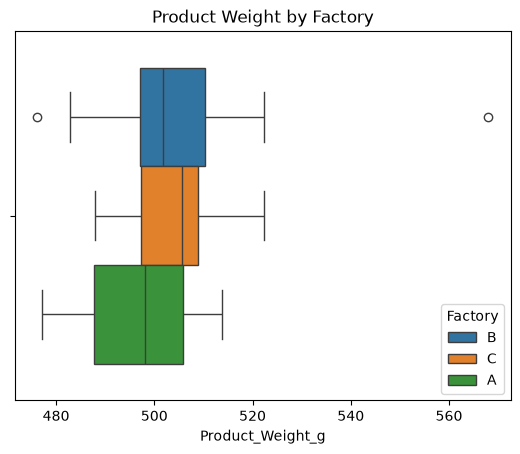

In [48]:
# Boxplot showing Factory B has more outliers.
sns.boxplot(data=df_clean, x='Product_Weight_g', hue='Factory').set(
    title='Product Weight by Factory'
)

[Text(0.5, 1.0, 'Spearman Correlation Between Quantitative Variables')]

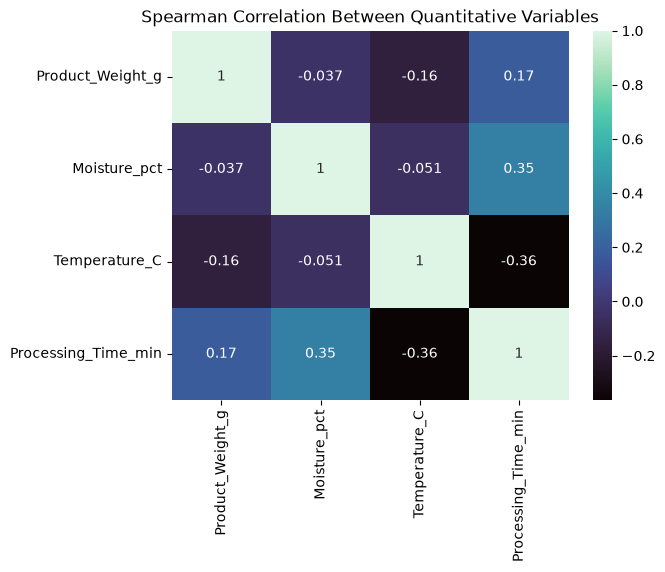

In [49]:
# heatmap showing correlation between quantitative features.
sns.heatmap(
    df_clean.corr(numeric_only=True, method='spearman'), annot=True, cmap='mako'
).set(title='Spearman Correlation Between Quantitative Variables')

[Text(0.5, 1.0, 'Batches by Quality Grade')]

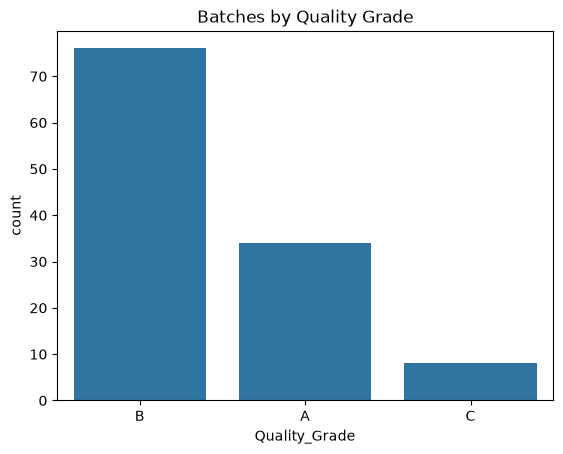

In [50]:
# Countplot to show differences in Quality_Grade
sns.countplot(data=df_clean, x='Quality_Grade').set(title='Batches by Quality Grade')

[Text(0.5, 1.0, 'Processing Time vs Temperature')]

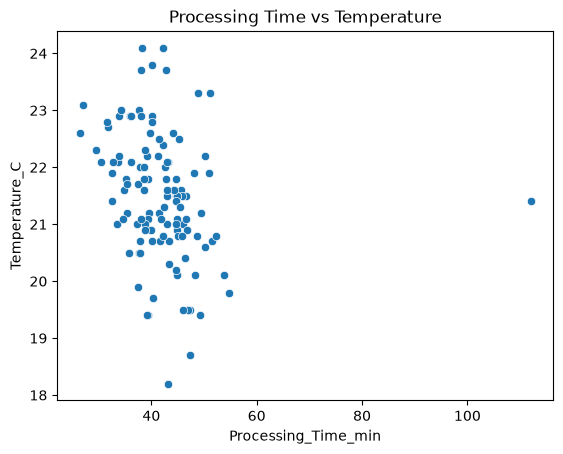

In [51]:
# Scatterplot to show the two most correlated items.
sns.scatterplot(data=df_clean, x='Processing_Time_min', y='Temperature_C').set(
    title='Processing Time vs Temperature'
)

### c) From the descriptive statistics and graphs, identify three analytically important findings. At least one finding must discuss uncertainty, an exception, or a pattern that should not be over-interpreted.

1. In the plot showing weight, it is possible to see the sole extreme batch is responsible for the skew.
2.  The majority class of the Quality_grade is B, with more than double the amount of A and more produced than both the others.
3.  The scatterplot shows the single 112 processing time data point as being an extreme outlier, weakening the mild negative correlation.

## Question 3 - Sampling uncertainty and the 500 g target
Treat the valid Product_Weight_g observations as a sample from the ongoing production process.

### a) Estimate the sample mean, sample standard deviation and standard error of the mean. Explain, in plain English, what the standard error means in this context.
The standard error is the standard deviation in the sample mean, from sample to sample of the `Product_Weight_g`. So if we took many samples from the whole population, their means would differ from the population by about 1.06g.

1. The sample mean is 501.6g.
2. The sample standard deviation is 11.57g.
3. The standard error of the mean is 1.06.

In [52]:
df_clean['Product_Weight_g'].mean()

np.float64(501.64033613445383)

In [53]:
df_clean['Product_Weight_g'].std()

np.float64(11.569050759646467)

In [54]:
df_clean['Product_Weight_g'].sem()

np.float64(1.0605331443411004)

### b) Formulate an appropriate hypothesis test for whether the true mean product weight differs from 500 g. Justify whether the test is one-tailed or two-tailed.
H0: μ = 500g, H1: μ ≠ 500g
I hypothesise that the true mean of the population does differ from 500g.
I will test this with a one-sample t-test.
This test does has to be two-tailed because we are testing if the weight differs from 500g. Even if the lower tail is higher than 500g, we must still examine how much it differs from the 500g on the higher tail as well. A t-test is sufficient because we have enough rows, and both the mean and median are similar, so it is likely that the mean is more or less normal.

### c) Carry out the test at the 5% significance level. Report the test statistic, degrees of freedom, p-value and conclusion in operational language
1. T-stat is 1.55
2. Degrees of Freedom is 118.
3. P-value is 0.125
   
At the 5% significance level, there is not enough evidence to state that the product weight differs from 500g. The estimated average is 501.6g and the true average lies between 499.54 and 503.74g, therefore we fail to reject the null.

In [ ]:
weights = df_clean['Product_Weight_g'].dropna()
t_stat, p_value = stats.ttest_1samp(weights, popmean=500)
dof = len(weights) - 1
print(t_stat, dof, p_value)

ci_low, ci_high = stats.t.interval(0.95, dof, loc=weights.mean(), scale=weights.sem())
print(ci_low, ci_high)

1.5467089767128008 118 0.12461125134433224
499.5401917792809 503.74048048962675


## Question 4 - Do factories differ in product weight?
Management wants to know whether Product_Weight_g differs systematically across Factory A, B and C.

### a) Use suitable numerical summaries and a graph to compare the factories.
The table demonstrates that Differrent factories have different product weights.
- Factory A has a mean and median below 500g.
- Factory B has a high STD, demonstrating more variety in product weight, with outliers on both ends.
- Factory C is the most consistent for producing weights close to 500g.  

  
  

| Factory | count | Mean | Median | SD | IQR | Min | Max |
|---|---|---|---|---|---|---|---|
| A | 44 | 497.13 | 498.15 | 10.31 | 18.10 | 477.20 | 513.80 |
| B | 40 | 504.21 | 501.80 | 14.18 | 13.10 | 476.20 | 568.00 |
| C | 35 | 504.37 | 505.60 | 7.61 | 11.55 | 487.90 | 522.30 |  


Boxplot showing that weight does differ between factories.  
  
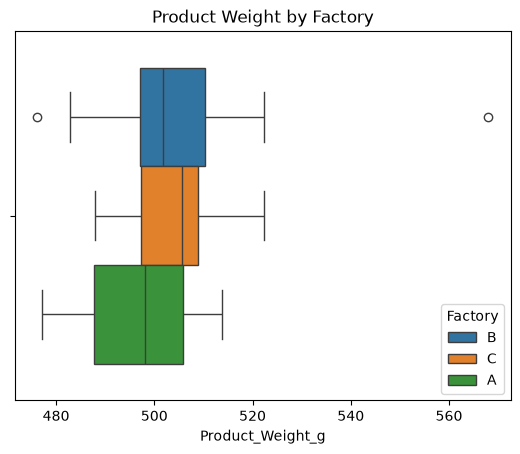  


In [57]:
df_clean.groupby('Factory')['Product_Weight_g'].agg(['count', 'mean', 'median', 'std', iqr, 'min', 'max']).round(2)

,count,mean,median,std,iqr,min,max
Factory,,,,,,,
A,44,497.13,498.15,10.31,18.10,477.2,513.8
B,40,504.21,501.80,14.18,13.10,476.2,568.0
C,35,504.37,505.60,7.61,11.55,487.9,522.3


### b) Select an appropriate inferential test. State the hypotheses and explain why the chosen test is appropriate.

The appropriate inferential test to examine if the product weight differs systematically would be the One-Way ANOVA. The null is that all factories produce the same average weight, and the alternative is that at least one factory's mean weight differs. This is an appropriate test because we are comparing the means of three groups, the outcome is a ratio level variable and a the grouping variable, Factory,is categorical, and the observations are independent. These factors allow us to use this test to make the comparison

H0: μA = μB = μC  
H1: at least one factory's mean weight differs.

### c) Check the relevant assumptions/conditions using appropriate diagnostics. If a condition is questionable, explain how that affects your test choice.
- Factory B has a right skewed distribution, rather than normal, meaning the ONe-Way ANOVA test could have issues producing reliable results. This is due to the outlier. The other factories have skew within normality.
- The groups are three independent factories with each batch originating in one.
- The highest STD of 14.18 divided by the lowest of 7.61 is 1.86, which is within the acceptable range for ANOVA.
  
Due to B being right-skewed, ANOVA may no longer be appropriate. The choices are to use it and examine the results, or change the test and use a method that is more resistant to outliers and skew, such as Kruskal–Wallis. I will keep ANOVA and examine another Kruskal–Wallis for comparison.

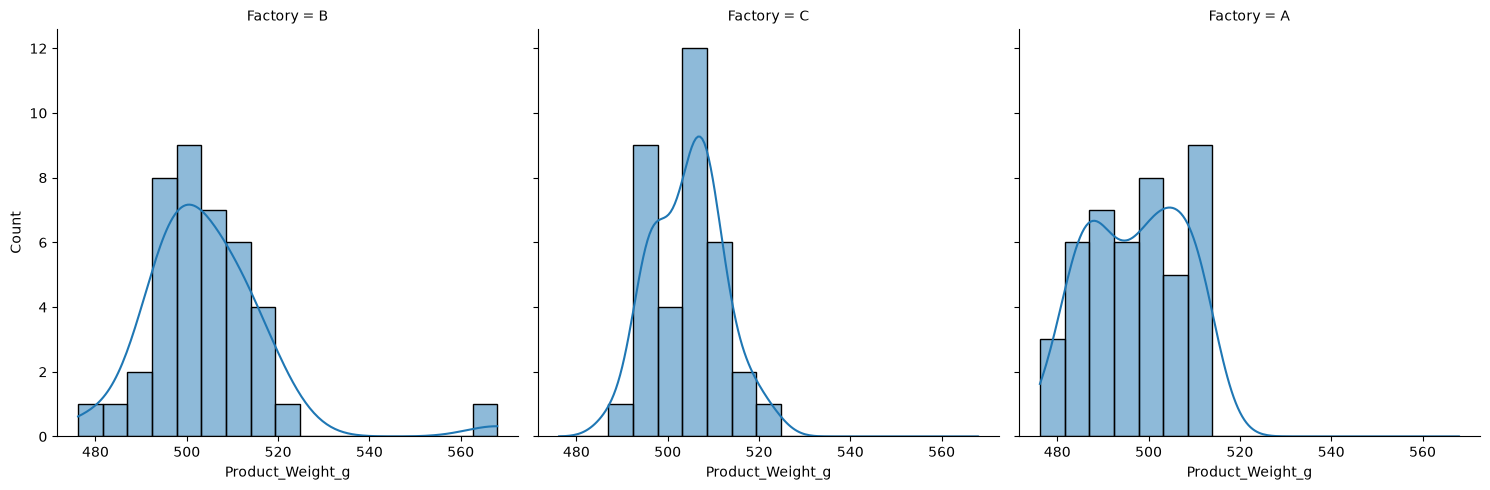

In [58]:
sns.displot(df_clean, x='Product_Weight_g', col='Factory', kde=True)

In [59]:
df_clean.groupby('Factory')['Product_Weight_g'].skew().round(2)

Factory
A   -0.09
B    2.22
C    0.11
Name: Product_Weight_g, dtype: float64

### d) Carry out the test and interpret the result. If the overall test is significant, state clearly what it does and does not establish, and identify the next analysis you would perform before claiming which factories differ.

1. One-Way ANOVA: F(2, 116) = 5.72, p = 0.004
2. Kruskal–Wallis: H = 9.45, df = 2, p = 0.009

At the 5% significance level, we reject the null. There is evidence that average product weight is not the same across all three factories. Kruskal–Wallis, which is not affected by Factory B's 568 g batch, reaches the same conclusion, so the result is not driven by that outlier.

This establishes that at least one factory produces a different average product weight from the others.

This does not establish:
- Which factories differ, or in which direction. The summary table suggests Factory A runs lower but the test does not confirm this.
- Why the factories differ. The data is observational, so we cannot presume any cause.

The next analysis I would compare each pair of factories (A vs B, A vs C, B vs C) using two-sample t-tests. Because running three tests increases the chance of a false positive, I would apply a Bonferroni correction, testing each pair at 0.05 / 3 ≈ 0.017 rather than 0.05.

In [60]:
groups = [g['Product_Weight_g'] for _, g in df_clean.groupby('Factory')]
print(stats.f_oneway(*groups))
print(stats.kruskal(*groups))

F_onewayResult(statistic=np.float64(5.721793683493605), pvalue=np.float64(0.004266974860741433))
KruskalResult(statistic=np.float64(9.453705986882385), pvalue=np.float64(0.008854291755006048))
